# 2. La base de datos: ETL, estructura, calidad y representatividad

Este capítulo cubre la sección 1 del enunciado:
- la ETL desde los archivos crudos del SGC;
- el diccionario de variables;
- la estructura de los datos y su tamaño (n, p, n/p y entidades);
- la calidad: faltantes con su patrón y mecanismo, duplicados y casi-duplicados, atípicos y valores
  imposibles o inconsistentes;
- los sesgos de muestreo y las consideraciones éticas.

**Alcance de los datos usados aquí.** La descripción de la calidad usa **todo** el catálogo, porque no
toma decisiones de modelado. Las decisiones (umbral de magnitud y tratamiento de atípicos) se
justifican **solo con el periodo de entrenamiento** (sismos hasta noviembre de 2020).

In [1]:
# Localiza la raíz del libro (la carpeta con _config.yml) para poder importar los módulos de src/
import sys
from pathlib import Path
raiz = Path.cwd().resolve()
while not (raiz / "_config.yml").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
# Librerías de análisis y módulos propios: configuración, datos, EDA, evaluación y utilidades del libro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import config as cfg, datos, eda, evaluacion as ev
from src.libro import md, tabla, mostrar_plotly
from src.eda import es, p_fmt
# Estilo común de los gráficos, semilla global (SEMILLA = 42) y formato de las tablas
eda.configurar_graficos()
cfg.fijar_semillas()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

## 2.1 Extracción, transformación y carga (ETL)

In [2]:
# Extracción: lee los 10 archivos crudos de los portales del SGC y resume cobertura y estados por archivo
crudo = datos.leer_crudos()
por_archivo = (crudo.groupby(["portal", "archivo"])
               .agg(registros=("time", "size"), desde=("time", "min"), hasta=("time", "max"),
                    estados=("estado", lambda s: ", ".join(f"{k}: {v}" for k, v in s.value_counts().items())))
               .reset_index().sort_values("desde"))
eda.guardar_tabla(por_archivo, "etl_archivos.csv")
por_archivo

,portal,archivo,registros,desde,hasta,estados
9,histórico (xlsx),reporte990.xlsx,7008,2004-01-01 01:16:10,2006-12-31 15:02:43,revisado: 7008
5,histórico (xlsx),reporte1087.xlsx,5121,2007-01-01 06:27:38,2009-12-31 14:43:32,revisado: 5121
6,histórico (xlsx),reporte212.xlsx,4771,2010-01-01 11:37:37,2012-12-31 22:47:23,revisado: 4771
8,histórico (xlsx),reporte961.xlsx,5266,2013-01-01 02:48:44,2015-12-31 18:37:57,revisado: 5266
7,histórico (xlsx),reporte323.xlsx,3016,2016-01-01 00:39:28,2018-02-27 15:13:26,revisado: 3016
4,actual (csv),Catalogo_Sismico_4.csv,1712,2018-03-01 10:26:44,2018-12-31 21:43:13,manual: 1712
3,actual (csv),Catalogo_Sismico_3.csv,3709,2019-01-01 06:42:41,2020-12-31 22:19:27,"manual: 3706, automatic: 3"
2,actual (csv),Catalogo_Sismico_2.csv,3513,2021-01-01 09:24:04,2022-12-31 13:20:39,"manual: 3511, automatic: 2"
1,actual (csv),Catalogo_Sismico_1.csv,4182,2023-01-01 00:45:28,2024-12-31 19:07:36,manual: 4182
0,actual (csv),Catalogo_Sismico.csv,4985,2025-01-01 03:42:33,2026-10-17 22:57:30,"manual: 4957, automatic: 28"


In [3]:
# Transformación: aplica las reglas de limpieza (bitácora de filas eliminadas) y verifica que el resultado coincide con el catálogo guardado
catalogo, bitacora = datos.limpiar(crudo)
eda.guardar_tabla(bitacora, "etl_bitacora.csv")
guardado = pd.read_csv(cfg.CATALOGO, parse_dates=["time"])
cols = ["time", "latitude", "longitude", "depth", "mag", "depto"]
fusion = catalogo[cols].merge(guardado[cols], how="outer", indicator=True)
coincide = bool((fusion["_merge"] == "both").all() and len(catalogo) == len(guardado))
bitacora

,regla,filas_antes,eliminadas,filas_despues
0,solución revisada por analista (Revisado/manua...,43283,33,43250
1,"fecha, coordenadas y magnitud presentes",43250,0,43250
2,"duplicados exactos (fecha-hora, lat, lon, magn...",43250,11,43239
3,sismo atribuido a un departamento colombiano (...,43239,2621,40618
4,magnitud >= 2.5,40618,0,40618
5,desde 2004-01-01,40618,0,40618


In [4]:
md(f"""**Interpretación.**
- **Cobertura de los archivos.** Los diez archivos cubren de forma contigua de {crudo.time.min():%Y-%m-%d} a {crudo.time.max():%Y-%m-%d}
  ({es(len(crudo), 0)} registros): el portal histórico va hasta febrero de 2018 y el actual empieza en marzo de 2018.
- **Reglas de limpieza (en este orden):**
  1. Solo la solución **revisada por un analista** (`Revisado` en el portal histórico, `manual` en el actual). Las
     {bitacora.eliminadas[0]} soluciones `automatic` son preliminares y suelen corregirse después.
  2. Se eliminan los **duplicados exactos** ({bitacora.eliminadas[2]}).
  3. Se descartan los **{es(bitacora.eliminadas[3], 0)} sismos sin departamento** (en el mar o en zonas fronterizas).
     La razón es **homogeneidad entre portales**: el portal histórico solo publica sismos con departamento (0 % sin
     departamento), mientras que el actual incluye el mar y los países vecinos. Conservarlos en 2018–2026 crearía un
     salto artificial de actividad en las celdas costeras y fronterizas justo al cambiar de portal.
- **Filtros sin efecto.** Las reglas de magnitud ≥ 2,5 y fecha ≥ 2004 no eliminan nada: los archivos ya se
  descargaron con esos filtros.
- **Resultado.** **{es(len(catalogo), 0)} sismos.** El catálogo guardado en `data/sismos_sgc_2004_2026.csv`
  {"**coincide exactamente**" if coincide else "**NO coincide**"} con el que produce esta ETL desde los crudos.""")

**Interpretación.**
- **Cobertura de los archivos.** Los diez archivos cubren de forma contigua de 2004-01-01 a 2026-10-17
  (43.283 registros): el portal histórico va hasta febrero de 2018 y el actual empieza en marzo de 2018.
- **Reglas de limpieza (en este orden):**
  1. Solo la solución **revisada por un analista** (`Revisado` en el portal histórico, `manual` en el actual). Las
     33 soluciones `automatic` son preliminares y suelen corregirse después.
  2. Se eliminan los **duplicados exactos** (11).
  3. Se descartan los **2.621 sismos sin departamento** (en el mar o en zonas fronterizas).
     La razón es **homogeneidad entre portales**: el portal histórico solo publica sismos con departamento (0 % sin
     departamento), mientras que el actual incluye el mar y los países vecinos. Conservarlos en 2018–2026 crearía un
     salto artificial de actividad en las celdas costeras y fronterizas justo al cambiar de portal.
- **Filtros sin efecto.** Las reglas de magnitud ≥ 2,5 y fecha ≥ 2004 no eliminan nada: los archivos ya se
  descargaron con esos filtros.
- **Resultado.** **40.618 sismos.** El catálogo guardado en `data/sismos_sgc_2004_2026.csv`
  **coincide exactamente** con el que produce esta ETL desde los crudos.

## 2.2 Diccionario de variables

Hay dos niveles de datos: el **catálogo** (una fila por sismo) y el **panel de modelado** (una fila
por celda y mes). Las variables del panel se derivan del catálogo **solo con sismos hasta el final del
mes *t***.

In [5]:
# Diccionario de variables del catálogo y del panel: tipo, unidad, significado y si se usa
dicc_cat = pd.DataFrame([
    ("time", "fecha-hora", "UTC", "Momento del origen del sismo", "sí"),
    ("latitude", "numérica continua", "grados (EPSG:4326)", "Latitud del epicentro", "sí"),
    ("longitude", "numérica continua", "grados (EPSG:4326)", "Longitud del epicentro", "sí"),
    ("depth", "numérica continua", "km", "Profundidad del hipocentro (negativa = sobre el nivel del mar)", "sí"),
    ("mag", "numérica continua", "magnitud local (Ml/MLr) o Mw", "Magnitud del sismo", "sí"),
    ("tipo_mag", "categórica", "—", "Escala de magnitud reportada (Ml, MLr_*, Mw, …)", "solo calidad"),
    ("fases", "numérica discreta", "conteo", "Número de fases sísmicas usadas en la localización", "solo calidad"),
    ("rms", "numérica continua", "s", "Residuo cuadrático medio de los tiempos de llegada", "solo calidad"),
    ("gap_az", "numérica continua", "grados", "Mayor hueco azimutal entre estaciones (cobertura de la red)", "solo calidad"),
    ("err_lat / err_lon / err_prof", "numérica continua", "km", "Error de localización en cada eje", "solo calidad"),
    ("depto", "categórica (35 niveles)", "—", "Departamento colombiano del epicentro", "sí (EDA)"),
    ("region", "texto", "—", "Municipio (portal histórico) o región descriptiva (portal actual)", "solo ETL"),
    ("estado", "categórica", "—", "Revisado/manual (revisado por analista) o automatic", "solo ETL"),
], columns=["variable", "tipo", "unidad", "significado", "se usa"])
dicc_panel = pd.DataFrame([
    ("y (objetivo)", "conteo entero ≥ 0", "sismos", "Sismos M ≥ 2,5 en la celda durante el mes t+1"),
    ("n_1m, n_3m, n_6m, n_12m", "conteo", "sismos", "Sismos en la celda en los últimos 1, 3, 6 y 12 meses (hasta t)"),
    ("n35_3m, n35_12m", "conteo", "sismos", "Sismos M ≥ 3,5 en la celda en los últimos 3 y 12 meses"),
    ("mag_media_3m, mag_media_12m", "continua (faltante si no hubo sismos)", "magnitud", "Magnitud media en la ventana"),
    ("mag_max_3m, mag_max_12m", "continua (faltante si no hubo sismos)", "magnitud", "Magnitud máxima en la ventana"),
    ("prof_media_hist", "continua", "km", "Profundidad media histórica de la celda (desde 2004 hasta t)"),
    ("vec_1m, vec_3m", "conteo", "sismos", "Sismos en las 8 celdas vecinas en el último mes / 3 meses (rezago espacial)"),
    ("n_mismo_mes_anio_prev", "conteo", "sismos", "Sismos de la celda en el mismo mes del año anterior (ingenuo estacional)"),
    ("sen_mes, cos_mes", "continua [-1, 1]", "—", "Codificación cíclica del mes objetivo"),
    ("lat, lon", "continua", "grados", "Centro de la celda"),
], columns=["variable", "tipo", "unidad", "significado"])
eda.guardar_tabla(dicc_cat, "diccionario_catalogo.csv")
eda.guardar_tabla(dicc_panel, "diccionario_panel.csv")
display(dicc_cat)
dicc_panel

,variable,tipo,unidad,significado,se usa
0,time,fecha-hora,UTC,Momento del origen del sismo,sí
1,latitude,numérica continua,grados (EPSG:4326),Latitud del epicentro,sí
2,longitude,numérica continua,grados (EPSG:4326),Longitud del epicentro,sí
3,depth,numérica continua,km,Profundidad del hipocentro (negativa = sobre e...,sí
4,mag,numérica continua,magnitud local (Ml/MLr) o Mw,Magnitud del sismo,sí
5,tipo_mag,categórica,—,"Escala de magnitud reportada (Ml, MLr_*, Mw, …)",solo calidad
6,fases,numérica discreta,conteo,Número de fases sísmicas usadas en la localiza...,solo calidad
7,rms,numérica continua,s,Residuo cuadrático medio de los tiempos de lle...,solo calidad
8,gap_az,numérica continua,grados,Mayor hueco azimutal entre estaciones (cobertu...,solo calidad
9,err_lat / err_lon / err_prof,numérica continua,km,Error de localización en cada eje,solo calidad


,variable,tipo,unidad,significado
0,y (objetivo),conteo entero ≥ 0,sismos,"Sismos M ≥ 2,5 en la celda durante el mes t+1"
1,"n_1m, n_3m, n_6m, n_12m",conteo,sismos,"Sismos en la celda en los últimos 1, 3, 6 y 12..."
2,"n35_3m, n35_12m",conteo,sismos,"Sismos M ≥ 3,5 en la celda en los últimos 3 y ..."
3,"mag_media_3m, mag_media_12m",continua (faltante si no hubo sismos),magnitud,Magnitud media en la ventana
4,"mag_max_3m, mag_max_12m",continua (faltante si no hubo sismos),magnitud,Magnitud máxima en la ventana
5,prof_media_hist,continua,km,Profundidad media histórica de la celda (desde...
6,"vec_1m, vec_3m",conteo,sismos,Sismos en las 8 celdas vecinas en el último me...
7,n_mismo_mes_anio_prev,conteo,sismos,Sismos de la celda en el mismo mes del año ant...
8,"sen_mes, cos_mes","continua [-1, 1]",—,Codificación cíclica del mes objetivo
9,"lat, lon",continua,grados,Centro de la celda


## 2.3 Estructura, tamaño y entidades

In [6]:
# Carga: construye el panel celda × mes desde el catálogo limpio y describe su estructura
ev_, n_meses = datos.preparar_eventos(guardado)
X, info = datos.construir_panel(ev_, n_meses)
tr, gp, te = datos.particion(info)
y = info["y"]
estructura = pd.DataFrame([
    ("Nivel catálogo: filas (sismos, meses completos)", es(len(ev_), 0)),
    ("Nivel catálogo: tipo", "proceso puntual espacio-temporal irregular"),
    ("Nivel panel: unidad de observación", "celda activa de 0,5° × mes"),
    ("Nivel panel: tipo", "panel espacio-temporal (longitudinal por celda) — ruta D"),
    ("Filas del panel (n)", es(len(y), 0)),
    ("Predictoras del modelo base (p)", X.shape[1]),
    ("Relación n/p", es(len(y) / X.shape[1], 0)),
    ("Entidades independientes: celdas activas", len(info["celdas"])),
    ("Entidades: meses objetivo", len(np.unique(info["tm"]))),
    ("Departamentos con sismos", guardado.depto.nunique()),
    ("Rango del objetivo (todo el panel)", f"{int(y.min())} a {int(y.max())}"),
    ("Rango del objetivo (entrenamiento)", f"{int(y[tr].min())} a {int(y[tr].max())}"),
    ("Media / mediana del objetivo (entrenamiento)", f"{es(y[tr].mean(), 2)} / {es(np.median(y[tr]), 0)}"),
    ("Filas duplicadas (celda, mes)", int(pd.DataFrame({'c': info['cc'], 't': info['tt']}).duplicated().sum())),
], columns=["medida", "valor"])
eda.guardar_tabla(estructura, "estructura_tamano.csv")
estructura

,medida,valor
0,"Nivel catálogo: filas (sismos, meses completos)",40.365
1,Nivel catálogo: tipo,proceso puntual espacio-temporal irregular
2,Nivel panel: unidad de observación,"celda activa de 0,5° × mes"
3,Nivel panel: tipo,panel espacio-temporal (longitudinal por celda...
4,Filas del panel (n),42.380
5,Predictoras del modelo base (p),18
6,Relación n/p,2.354
7,Entidades independientes: celdas activas,163
8,Entidades: meses objetivo,260
9,Departamentos con sismos,35


In [7]:
md(f"""**Interpretación.**
- **Dos niveles de datos.** El catálogo es un **proceso puntual** (cada sismo con tiempo y coordenadas, a intervalos irregulares).
  Para modelar se agrega en un **panel regular** celda × mes.
- **Tamaño del panel.** Tiene {es(len(y), 0)} filas y {X.shape[1]} predictoras: n/p ≈ {es(len(y) / X.shape[1], 0)}, holgado para
  modelos lineales y no lineales.
- **Tamaño efectivo.** Es menor que n: son {len(info['celdas'])} series (celdas) de hasta {len(np.unique(info['tm']))} meses, y
  las filas de un mismo mes están correlacionadas porque comparten el estado sísmico regional. Por eso la incertidumbre se
  estima remuestreando meses (capítulos 11 y siguientes).
- **Sin duplicados.** Cada par (celda, mes) aparece una sola vez.""")

**Interpretación.**
- **Dos niveles de datos.** El catálogo es un **proceso puntual** (cada sismo con tiempo y coordenadas, a intervalos irregulares).
  Para modelar se agrega en un **panel regular** celda × mes.
- **Tamaño del panel.** Tiene 42.380 filas y 18 predictoras: n/p ≈ 2.354, holgado para
  modelos lineales y no lineales.
- **Tamaño efectivo.** Es menor que n: son 163 series (celdas) de hasta 260 meses, y
  las filas de un mismo mes están correlacionadas porque comparten el estado sísmico regional. Por eso la incertidumbre se
  estima remuestreando meses (capítulos 11 y siguientes).
- **Sin duplicados.** Cada par (celda, mes) aparece una sola vez.

## 2.4 Valores faltantes: patrón

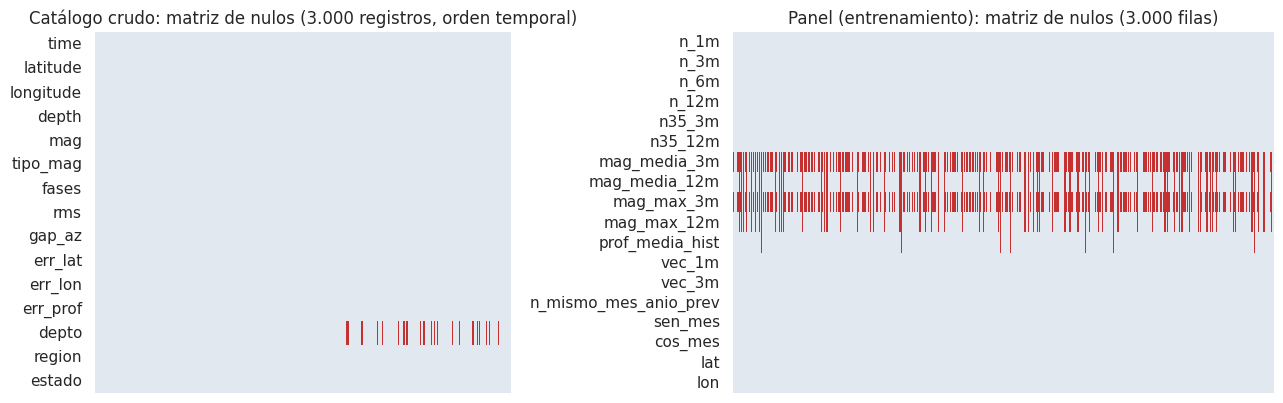

portal,actual (csv),histórico (xlsx)
time,0.00,0.00
latitude,0.00,0.00
longitude,0.00,0.00
depth,0.00,0.00
mag,0.00,0.00
tipo_mag,0.00,0.00
fases,0.00,0.00
rms,0.00,0.01
gap_az,0.00,0.01
err_lat,0.00,0.01


,"% faltante (panel, entrenamiento)"
mag_media_3m,51.88
mag_media_12m,16.08
mag_max_3m,51.88
mag_max_12m,16.08
prof_media_hist,1.43


In [8]:
# Valores faltantes: porcentaje por portal en el crudo y por variable en el panel (solo entrenamiento) y su patrón
faltantes_crudo = crudo.drop(columns=["portal", "archivo"]).isna().groupby(crudo.portal).mean().T * 100
faltantes_panel = X.iloc[tr].isna().mean().to_frame("% faltante (panel, entrenamiento)") * 100
eda.guardar_tabla(faltantes_crudo.reset_index(), "faltantes_crudo.csv")
eda.guardar_tabla(faltantes_panel.reset_index(), "faltantes_panel.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
muestra = crudo.sample(3000, random_state=cfg.SEMILLA).sort_values("time")
sns.heatmap(muestra.drop(columns=["portal", "archivo"]).isna().T, cbar=False, cmap=["#e2e8f0", "#c53030"], ax=axes[0],
            xticklabels=False)
axes[0].set_title("Catálogo crudo: matriz de nulos (3.000 registros, orden temporal)")
mp = X.iloc[tr].sample(3000, random_state=cfg.SEMILLA)
sns.heatmap(mp.isna().T, cbar=False, cmap=["#e2e8f0", "#c53030"], ax=axes[1], xticklabels=False)
axes[1].set_title("Panel (entrenamiento): matriz de nulos (3.000 filas)")
plt.tight_layout(); eda.guardar_figura(fig, "02_matriz_nulos.png"); plt.show()
display(faltantes_crudo.round(2))
faltantes_panel[faltantes_panel.iloc[:, 0] > 0].round(2)

## 2.5 Valores faltantes: mecanismo (MCAR, MAR o MNAR)

Hay dos tipos de faltantes, con mecanismos distintos:

1. **`depto` en el catálogo crudo.** Se evalúa si depende de variables observadas, comparando las
   distribuciones de los registros completos e incompletos y midiendo cuánto predicen las coordenadas
   la ausencia.
2. **Magnitudes medias y máximas en el panel.** Faltan cuando la celda no tuvo sismos en la ventana.
   Es un faltante **estructural** («no aplica»). Se aplica la prueba MCAR de Little
   {cite}`little1988test` y se verifica la regla de forma directa.

In [9]:
# Mecanismo del faltante de depto: ¿se predice con las demás variables? (si sí, es MAR y no MCAR)
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
nuevo = crudo[crudo.portal == "actual (csv)"].copy()
nuevo["falta_depto"] = nuevo.depto.isna().astype(int)
filas = []
for v in ["latitude", "longitude", "depth", "mag", "err_lat", "err_prof", "gap_az"]:
    a, b = nuevo.loc[nuevo.falta_depto == 1, v].dropna(), nuevo.loc[nuevo.falta_depto == 0, v].dropna()
    u, p = stats.mannwhitneyu(a, b)
    filas.append({"variable": v, "mediana_sin_depto": a.median(), "mediana_con_depto": b.median(),
                  "U": u, "p": p, "biserial_rangos": eda.biserial_rangos(u, len(a), len(b))})
mec = pd.DataFrame(filas)
mec["p_holm"] = eda.holm(mec.p)
auc_coord = cross_val_score(RandomForestClassifier(200, min_samples_leaf=5, random_state=cfg.SEMILLA, n_jobs=-1),
                            nuevo[["latitude", "longitude"]], nuevo.falta_depto, cv=5, scoring="roc_auc").mean()
eda.guardar_tabla(mec, "mecanismo_faltantes_depto.csv")
mec

,variable,mediana_sin_depto,mediana_con_depto,U,p,biserial_rangos,p_holm
0,latitude,6.3275,6.778,22028498.0,4.988959e-12,-0.084150,1.496688e-11
1,longitude,-77.9530,-73.200,4975521.0,0.000000e+00,0.755126,0.000000e+00
2,depth,13.0350,138.090,5738560.5,0.000000e+00,0.717572,0.000000e+00
3,mag,2.8000,2.800,22008974.0,5.889475e-12,-0.083189,1.496688e-11
4,err_lat,2.2170,2.141,23838732.5,7.016810e-46,-0.173242,2.806724e-45
5,err_prof,3.4000,4.200,18899694.5,9.960586e-09,0.069836,9.960586e-09
6,gap_az,156.0000,67.000,36679819.5,0.000000e+00,-0.805227,0.000000e+00


In [10]:
# Faltantes de magnitud en el panel: se verifica que solo ocurren cuando no hubo sismos en la ventana, y prueba de Little
cols_mag = ["mag_media_3m", "mag_media_12m", "mag_max_3m", "mag_max_12m"]
Xtr = X.iloc[tr]
regla = {c: bool((Xtr[c].isna() == (Xtr["n_3m" if "3m" in c else "n_12m"] == 0)).all()) for c in cols_mag}
little = eda.prueba_little_mcar(Xtr[cols_mag + ["n_1m", "n_3m", "n_12m", "vec_1m", "prof_media_hist"]].sample(8000, random_state=cfg.SEMILLA))
md(f"""**Interpretación (mecanismo).**

- **`depto` → MAR, explicado por la ubicación.** Solo falta en el portal actual. Los registros sin departamento difieren con
  fuerza de los completos en **longitud** (biserial de rangos {es(mec.loc[mec.variable == 'longitude', 'biserial_rangos'].iloc[0], 2)}: están más al
  occidente, en el Pacífico) y **profundidad** ({es(mec.loc[mec.variable == 'depth', 'biserial_rangos'].iloc[0], 2)}: son más superficiales).
  En latitud y magnitud la diferencia es pequeña (|r| ≈ {es(abs(mec.loc[mec.variable == 'latitude', 'biserial_rangos'].iloc[0]), 2)}),
  aunque significativa por el tamaño de muestra (p de Holm {p_fmt(mec.p_holm.max())} en todas las variables).
  - Un bosque aleatorio que **solo usa las coordenadas** predice la ausencia con AUC = {es(auc_coord, 3)}.
  - Por tanto **no es MCAR**: la ausencia depende de la ubicación observada (mar y fronteras). No se imputa. Esos sismos se
    excluyen por la regla de homogeneidad entre portales (sección 2.1), y la consecuencia es un sesgo de cobertura que se
    discute en la sección 2.9.
  - Los sismos sin departamento tienen un **gap azimutal mucho mayor** (mediana {es(mec.loc[mec.variable == 'gap_az', 'mediana_sin_depto'].iloc[0], 0)}° frente a
    {es(mec.loc[mec.variable == 'gap_az', 'mediana_con_depto'].iloc[0], 0)}°): en el mar la red los «ve» desde un solo lado, así que su localización es menos confiable.
- **Magnitudes del panel → faltante estructural.** La regla «falta si y solo si no hubo sismos en la ventana» se cumple en
  {sum(regla.values())} de {len(regla)} variables. Por definición no es MCAR, y la prueba de Little lo confirma
  (χ² = {es(little['chi2'], 1)}, g.l. = {little['gl']}, p {p_fmt(little['p'])}).
  - Es un faltante «no aplica»: no hay una magnitud que observar.
  - **Tratamiento** (capítulo 10): imputación dentro del Pipeline, ajustada solo con entrenamiento. Para los modelos de
    árboles da igual el valor elegido, porque `n_3m = 0` ya marca el caso.""")

**Interpretación (mecanismo).**

- **`depto` → MAR, explicado por la ubicación.** Solo falta en el portal actual. Los registros sin departamento difieren con
  fuerza de los completos en **longitud** (biserial de rangos 0,76: están más al
  occidente, en el Pacífico) y **profundidad** (0,72: son más superficiales).
  En latitud y magnitud la diferencia es pequeña (|r| ≈ 0,08),
  aunque significativa por el tamaño de muestra (p de Holm < 0,001 en todas las variables).
  - Un bosque aleatorio que **solo usa las coordenadas** predice la ausencia con AUC = 0,998.
  - Por tanto **no es MCAR**: la ausencia depende de la ubicación observada (mar y fronteras). No se imputa. Esos sismos se
    excluyen por la regla de homogeneidad entre portales (sección 2.1), y la consecuencia es un sesgo de cobertura que se
    discute en la sección 2.9.
  - Los sismos sin departamento tienen un **gap azimutal mucho mayor** (mediana 156° frente a
    67°): en el mar la red los «ve» desde un solo lado, así que su localización es menos confiable.
- **Magnitudes del panel → faltante estructural.** La regla «falta si y solo si no hubo sismos en la ventana» se cumple en
  4 de 4 variables. Por definición no es MCAR, y la prueba de Little lo confirma
  (χ² = 3.103,8, g.l. = 16, p < 0,001).
  - Es un faltante «no aplica»: no hay una magnitud que observar.
  - **Tratamiento** (capítulo 10): imputación dentro del Pipeline, ajustada solo con entrenamiento. Para los modelos de
    árboles da igual el valor elegido, porque `n_3m = 0` ya marca el caso.

## 2.6 Duplicados exactos y casi-duplicados

In [11]:
# Duplicados probables: pares de sismos consecutivos muy cercanos en tiempo, distancia y magnitud
c = catalogo.sort_values("time").reset_index(drop=True)
dt = c.time.diff().dt.total_seconds().fillna(1e9).to_numpy()
dd = eda.haversine_km(c.latitude.shift().to_numpy(), c.longitude.shift().to_numpy(), c.latitude.to_numpy(), c.longitude.to_numpy())
dm = np.abs(c.mag.diff().to_numpy())
filas = []
for seg, km, dmag in ((2, 5, 0.1), (5, 10, 0.2), (10, 20, 0.3), (60, 50, 0.5)):
    casi = (dt <= seg) & (dd <= km) & (dm <= dmag)
    filas.append({"criterio": f"≤ {seg} s, ≤ {km} km, |ΔM| ≤ {dmag}", "pares_consecutivos": int(np.nansum(casi))})
casi_dup = pd.DataFrame(filas)
frontera = c[(c.time >= "2018-02-20") & (c.time <= "2018-03-10")]
eda.guardar_tabla(casi_dup, "casi_duplicados.csv")
casi_dup

,criterio,pares_consecutivos
0,"≤ 2 s, ≤ 5 km, |ΔM| ≤ 0.1",27
1,"≤ 5 s, ≤ 10 km, |ΔM| ≤ 0.2",41
2,"≤ 10 s, ≤ 20 km, |ΔM| ≤ 0.3",51
3,"≤ 60 s, ≤ 50 km, |ΔM| ≤ 0.5",171


In [12]:
md(f"""**Interpretación.**
- **Duplicados exactos.** La ETL eliminó {bitacora.eliminadas[2]} (misma fecha-hora, coordenadas y magnitud).
- **Casi-duplicados.** Se buscan sismos consecutivos casi idénticos en tiempo, posición y magnitud. Con criterios estrictos
  (≤ 2–5 s y ≤ 5–10 km) hay {casi_dup.pares_consecutivos.iloc[0]}–{casi_dup.pares_consecutivos.iloc[1]} pares, menos del 0,1 % del catálogo.
- **Por qué no se borran.** Con criterios laxos aparecen más pares, pero ahí ya no son duplicados: son **sismos reales muy
  seguidos** (réplicas y enjambres, como el nido de Bucaramanga). Borrarlos eliminaría justamente el agrupamiento que el
  modelo debe aprender.
- **Cambio de portal.** En la frontera entre portales (20-feb a 10-mar de 2018) hay {len(frontera)} sismos y ningún solapamiento
  de fechas entre archivos: el corte es limpio.""")

**Interpretación.**
- **Duplicados exactos.** La ETL eliminó 11 (misma fecha-hora, coordenadas y magnitud).
- **Casi-duplicados.** Se buscan sismos consecutivos casi idénticos en tiempo, posición y magnitud. Con criterios estrictos
  (≤ 2–5 s y ≤ 5–10 km) hay 27–41 pares, menos del 0,1 % del catálogo.
- **Por qué no se borran.** Con criterios laxos aparecen más pares, pero ahí ya no son duplicados: son **sismos reales muy
  seguidos** (réplicas y enjambres, como el nido de Bucaramanga). Borrarlos eliminaría justamente el agrupamiento que el
  modelo debe aprender.
- **Cambio de portal.** En la frontera entre portales (20-feb a 10-mar de 2018) hay 55 sismos y ningún solapamiento
  de fechas entre archivos: el corte es limpio.

## 2.7 Valores atípicos (catálogo, periodo de entrenamiento)

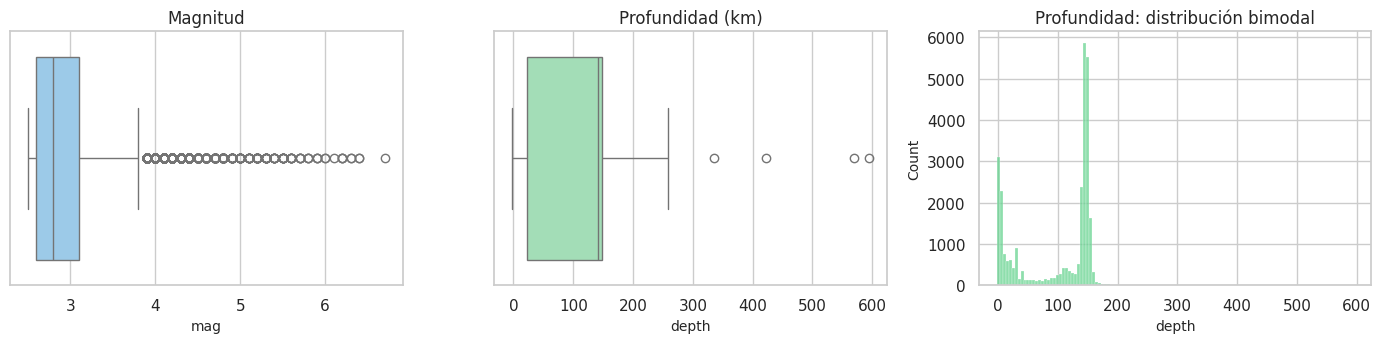

,media,mediana,desv_est,mín,p99,máx,asimetría,curtosis,atípicos_IQR_%
mag,2.93,2.80,0.46,2.50,4.50,6.70,1.80,4.45,5.42
depth,98.50,140.70,62.42,-1.99,161.64,594.80,-0.60,-1.13,0.01
latitude,6.29,6.81,1.78,-2.65,11.23,13.67,-0.55,2.11,19.57
longitude,-74.14,-73.16,1.81,-81.96,-71.44,-70.15,-1.31,0.73,6.80


In [13]:
# Atípicos del catálogo (solo entrenamiento): resumen numérico y diagramas de caja
cat_tr = guardado[guardado.time < datos.fecha_de_mes(info["m_test"] - cfg.GAP_MESES)[0]]
desc = eda.resumen_numerico(cat_tr[["mag", "depth", "latitude", "longitude"]])
eda.guardar_tabla(desc.reset_index(), "atipicos_catalogo.csv")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
sns.boxplot(x=cat_tr.mag, ax=axes[0], color="#90cdf4"); axes[0].set_title("Magnitud")
sns.boxplot(x=cat_tr.depth, ax=axes[1], color="#9ae6b4"); axes[1].set_title("Profundidad (km)")
sns.histplot(cat_tr.depth, bins=120, ax=axes[2], color="#68d391"); axes[2].set_title("Profundidad: distribución bimodal")
plt.tight_layout(); eda.guardar_figura(fig, "02_atipicos_boxplots.png"); plt.show()
desc[["media", "mediana", "desv_est", "mín", "p99", "máx", "asimetría", "curtosis", "atípicos_IQR_%"]].round(2)

In [14]:
# Profundidad en el nido de Bucaramanga, para interpretar la bimodalidad
prof_nido = cat_tr[(cat_tr.latitude.between(6.6, 7.0)) & (cat_tr.longitude.between(-73.3, -72.9))]
md(f"""**Interpretación.**
- **Magnitud.** Asimetría {es(desc.loc['mag', 'asimetría'], 2)}. El {es(desc.loc['mag', 'atípicos_IQR_%'], 1)} % de los sismos supera la valla
  de Tukey, hasta M {es(desc.loc['mag', 'máx'], 1)}. No son errores: la ley de Gutenberg-Richter (Gutenberg y Richter, 1944)
  predice exactamente esa cola exponencial (sección 2.9). **Se conservan.**
- **Profundidad.** La distribución es **bimodal**, sin rarezas de medición:
  - un grupo superficial de corteza (< 40 km);
  - un grupo intermedio alrededor de {es(prof_nido.depth.median(), 0)} km, que es el **nido sísmico de Bucaramanga**
    ({es(len(prof_nido) / len(cat_tr), 0, pct=True)} de los sismos del entrenamiento en una zona de unos 40 × 40 km).
- **La regla IQR casi no marca atípicos de profundidad** ({es(desc.loc['depth', 'atípicos_IQR_%'], 2)} %) porque la distribución bimodal ensancha el rango
  intercuartílico; no por eso hay que usarla a ciegas. Los sismos de más de 200 km ({es((cat_tr.depth > 200).mean(), 2, pct=True)}, hasta
  {es(desc.loc['depth', 'máx'], 0)} km) son reales, de la placa en subducción, y se conservan.
- **Tratamiento.**
  - No se recortan ni se eliminan sismos.
  - El objetivo y los conteos se modelan en escala log1p, que amortigua las colas.
  - Los atípicos del **panel** (enjambres con cientos de sismos en una celda-mes) se analizan en los capítulos 3 y 6.""")

**Interpretación.**
- **Magnitud.** Asimetría 1,80. El 5,4 % de los sismos supera la valla
  de Tukey, hasta M 6,7. No son errores: la ley de Gutenberg-Richter (Gutenberg y Richter, 1944)
  predice exactamente esa cola exponencial (sección 2.9). **Se conservan.**
- **Profundidad.** La distribución es **bimodal**, sin rarezas de medición:
  - un grupo superficial de corteza (< 40 km);
  - un grupo intermedio alrededor de 147 km, que es el **nido sísmico de Bucaramanga**
    (51 % de los sismos del entrenamiento en una zona de unos 40 × 40 km).
- **La regla IQR casi no marca atípicos de profundidad** (0,01 %) porque la distribución bimodal ensancha el rango
  intercuartílico; no por eso hay que usarla a ciegas. Los sismos de más de 200 km (0,06 %, hasta
  595 km) son reales, de la placa en subducción, y se conservan.
- **Tratamiento.**
  - No se recortan ni se eliminan sismos.
  - El objetivo y los conteos se modelan en escala log1p, que amortigua las colas.
  - Los atípicos del **panel** (enjambres con cientos de sismos en una celda-mes) se analizan en los capítulos 3 y 6.

## 2.8 Valores imposibles o inconsistentes

In [15]:
# Chequeos de valores imposibles: coordenadas, fechas, magnitudes y profundidades fuera de rango
chequeos = pd.DataFrame([
    ("latitud fuera de [-90, 90]", int((~crudo.latitude.between(-90, 90)).sum())),
    ("longitud fuera de [-180, 180]", int((~crudo.longitude.between(-180, 180)).sum())),
    ("coordenadas (0, 0)", int(((crudo.latitude == 0) & (crudo.longitude == 0)).sum())),
    ("lat/lon posiblemente invertidas (lat < -10 o lon > -60)", int(((crudo.latitude < -10) | (crudo.longitude > -60)).sum())),
    (f"fuera del área de estudio ({cfg.LAT_MIN}..{cfg.LAT_MAX}, {cfg.LON_MIN}..{cfg.LON_MAX})", int((~crudo.latitude.between(cfg.LAT_MIN, cfg.LAT_MAX) | ~crudo.longitude.between(cfg.LON_MIN, cfg.LON_MAX)).sum())),
    ("magnitud fuera de [-1, 10]", int((~crudo.mag.between(-1, 10)).sum())),
    ("profundidad negativa (sobre el nivel del mar)", int((crudo.depth < 0).sum())),
    ("profundidad exactamente 0 km (profundidad fijada)", int((crudo.depth == 0).sum())),
    ("profundidad > 700 km (imposible físicamente)", int((crudo.depth > 700).sum())),
    ("errores de localización negativos", int((crudo[["err_lat", "err_lon", "err_prof"]] < 0).sum().sum())),
    ("errores de localización = 99,9 km (tope del localizador)", int((crudo[["err_lat", "err_lon"]] >= 99.9).any(axis=1).sum())),
    ("gap azimutal fuera de [0, 360]", int((~crudo.gap_az.dropna().between(0, 360)).sum())),
    ("fechas futuras (> fecha de descarga)", int((crudo.time > pd.Timestamp("2026-10-18")).sum())),
    ("nombres de departamento con variantes de escritura", int(crudo.depto.dropna().nunique() - guardado.depto.nunique())),
], columns=["chequeo", "registros"])
eda.guardar_tabla(chequeos, "valores_imposibles.csv")
chequeos

,chequeo,registros
0,"latitud fuera de [-90, 90]",0
1,"longitud fuera de [-180, 180]",0
2,"coordenadas (0, 0)",0
3,lat/lon posiblemente invertidas (lat < -10 o l...,0
4,"fuera del área de estudio (-5.0..14.0, -82.0.....",0
5,"magnitud fuera de [-1, 10]",0
6,profundidad negativa (sobre el nivel del mar),241
7,profundidad exactamente 0 km (profundidad fijada),2074
8,profundidad > 700 km (imposible físicamente),0
9,errores de localización negativos,0


In [16]:
# Profundidades negativas: cuántas hay y de qué magnitud
neg = crudo[crudo.depth < 0]
md(f"""**Interpretación.**
- **Coordenadas, magnitudes, fechas y gap azimutal.** Ningún valor imposible.
- **Profundidades negativas** ({len(neg)}, mínimo {es(neg.depth.min(), 1)} km). Son plausibles: la profundidad se mide respecto al nivel
  del mar, y un sismo muy superficial bajo una montaña puede quedar «por encima» de él (el mínimo, unos 2 km, es menor que la
  altura de la cordillera). Se conservan.
  En la variable `prof_media_hist` se recortan a 0 para que la profundidad media no quede sesgada por la convención.
- **Profundidades exactamente 0 km** ({es((crudo.depth == 0).sum(), 0)}). Son profundidades **fijadas por el localizador**
  cuando no se pudo resolver, no medidas reales. Se marcan como una limitación de la variable profundidad, que no es el
  objetivo.
- **Errores de localización en el tope de 99,9 km** ({(crudo[['err_lat', 'err_lon']] >= 99.9).any(axis=1).sum()} registros). Son
  soluciones mal restringidas, casi todas en el mar o en la frontera, y la ETL ya las excluye por no tener departamento.
- **Nombres de departamento.** Las variantes de escritura (tildes, `_`, «San Andrés» largo) se **normalizaron**: mayúsculas
  sin tildes y nombre corto de San Andrés.
- **Escalas de magnitud.** El portal histórico solo reporta Ml; el actual reporta varias variantes (MLr_1…MLr_4, MLr, Mw, …).
  Es una **posible inconsistencia de unidades**: si la calibración de la magnitud local cambió con el portal, un mismo sismo podría
  quedar un poco por encima o por debajo del umbral de 2,5. Su efecto se mide en la sección 2.9 (completitud y valor *b* por año)
  y como deriva en el capítulo 7.""")

**Interpretación.**
- **Coordenadas, magnitudes, fechas y gap azimutal.** Ningún valor imposible.
- **Profundidades negativas** (241, mínimo -2,0 km). Son plausibles: la profundidad se mide respecto al nivel
  del mar, y un sismo muy superficial bajo una montaña puede quedar «por encima» de él (el mínimo, unos 2 km, es menor que la
  altura de la cordillera). Se conservan.
  En la variable `prof_media_hist` se recortan a 0 para que la profundidad media no quede sesgada por la convención.
- **Profundidades exactamente 0 km** (2.074). Son profundidades **fijadas por el localizador**
  cuando no se pudo resolver, no medidas reales. Se marcan como una limitación de la variable profundidad, que no es el
  objetivo.
- **Errores de localización en el tope de 99,9 km** (26 registros). Son
  soluciones mal restringidas, casi todas en el mar o en la frontera, y la ETL ya las excluye por no tener departamento.
- **Nombres de departamento.** Las variantes de escritura (tildes, `_`, «San Andrés» largo) se **normalizaron**: mayúsculas
  sin tildes y nombre corto de San Andrés.
- **Escalas de magnitud.** El portal histórico solo reporta Ml; el actual reporta varias variantes (MLr_1…MLr_4, MLr, Mw, …).
  Es una **posible inconsistencia de unidades**: si la calibración de la magnitud local cambió con el portal, un mismo sismo podría
  quedar un poco por encima o por debajo del umbral de 2,5. Su efecto se mide en la sección 2.9 (completitud y valor *b* por año)
  y como deriva en el capítulo 7.

## 2.9 Sesgos de muestreo y representatividad

Tres fuentes de sesgo propias de un catálogo sísmico:

1. **Completitud de la red.** La red detecta mejor donde tiene más estaciones, y la red crece con los
   años. Se estima la **magnitud de completitud** Mc por año con el método de máxima curvatura, y el
   valor *b* de Gutenberg-Richter por máxima verosimilitud {cite}`aki1965maximum`.
2. **Cobertura espacial.** Quedan fuera los sismos en el mar o en las fronteras (sección 2.1).
3. **Cambio de portal y de escala de magnitud** en 2018.

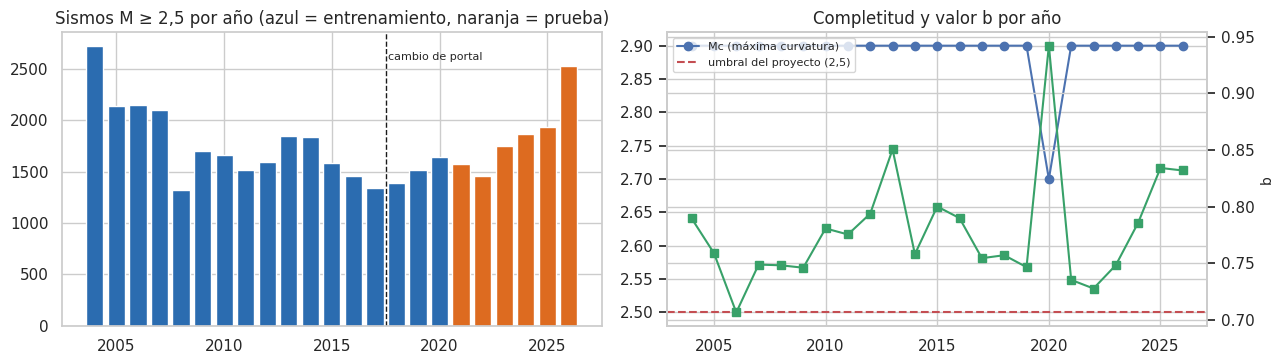

,año,sismos,Mc_max_curvatura,b_Aki,n_sobre_Mc,portal,periodo
0,2004,2719,2.9,0.79,1015,histórico,entrenamiento
1,2005,2141,2.9,0.76,810,histórico,entrenamiento
2,2006,2148,2.9,0.71,846,histórico,entrenamiento
3,2007,2095,2.9,0.75,835,histórico,entrenamiento
4,2008,1317,2.9,0.75,519,histórico,entrenamiento
5,2009,1701,2.9,0.75,623,histórico,entrenamiento
6,2010,1666,2.9,0.78,577,histórico,entrenamiento
7,2011,1514,2.9,0.78,567,histórico,entrenamiento
8,2012,1589,2.9,0.79,514,histórico,entrenamiento
9,2013,1845,2.9,0.85,629,histórico,entrenamiento


In [17]:
# Magnitud de completitud (Mc) por máxima curvatura y valor b de Gutenberg-Richter (Aki) por periodo
def mc_maxima_curvatura(m, paso=0.1):
    bins = np.arange(m.min(), m.max() + paso, paso)
    h, b = np.histogram(m, bins)
    return float(b[np.argmax(h)] + 0.2)          # corrección habitual de +0,2

def b_aki(m, mc, paso=0.1):
    m = m[m >= mc]
    return float(np.log10(np.e) / (m.mean() - (mc - paso / 2))), len(m)

filas = []
for anio, g in guardado.groupby(guardado.time.dt.year):
    mc = mc_maxima_curvatura(g.mag.to_numpy())
    b, n = b_aki(g.mag.to_numpy(), max(mc, cfg.M_MIN))
    filas.append({"año": anio, "sismos": len(g), "Mc_max_curvatura": mc, "b_Aki": b, "n_sobre_Mc": n,
                  "portal": "histórico" if anio < 2018 else ("cambio" if anio == 2018 else "actual"),
                  "periodo": "entrenamiento" if anio <= 2020 else "prueba"})
compl = pd.DataFrame(filas)
eda.guardar_tabla(compl, "completitud_por_anio.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(compl["año"], compl.sismos, color=np.where(compl.periodo == "entrenamiento", "#2b6cb0", "#dd6b20"))
axes[0].axvline(2017.5, ls="--", c="k", lw=1); axes[0].text(2017.6, compl.sismos.max() * 0.95, "cambio de portal", fontsize=8)
axes[0].set_title("Sismos M ≥ 2,5 por año (azul = entrenamiento, naranja = prueba)")
axes[1].plot(compl["año"], compl.Mc_max_curvatura, "o-", label="Mc (máxima curvatura)")
axes[1].axhline(cfg.M_MIN, c="r", ls="--", label="umbral del proyecto (2,5)")
ax2 = axes[1].twinx(); ax2.plot(compl["año"], compl.b_Aki, "s-", c="#38a169", label="b (Aki)"); ax2.set_ylabel("b")
axes[1].set_title("Completitud y valor b por año"); axes[1].legend(loc="upper left", fontsize=8)
plt.tight_layout(); eda.guardar_figura(fig, "02_completitud.png"); plt.show()
compl.round(2)

In [18]:
# Resumen de la completitud en el entrenamiento
ctr = compl[compl.periodo == "entrenamiento"]
md(f"""**Interpretación.**
- **El catálogo no está completo desde M 2,5.** Con el método de máxima curvatura (+0,2), la Mc del entrenamiento es
  {es(ctr.Mc_max_curvatura.mode()[0], 1)} en {int((ctr.Mc_max_curvatura == ctr.Mc_max_curvatura.mode()[0]).sum())} de {len(ctr)} años (mínimo
  {es(ctr.Mc_max_curvatura.min(), 1)}). Entre M 2,5 y la Mc, la red detecta solo una parte de los sismos que ocurren.
- **Es un sesgo de nivel, no de tendencia.** La Mc es prácticamente **constante** en el tiempo, incluido el cambio de portal
  de 2018. Los conteos subestiman la actividad real en una proporción parecida todos los años, así que **siguen siendo
  comparables entre periodos**, que es lo que necesita un pronóstico mes a mes.
- **Por qué se conserva M ≥ 2,5.** Subir el umbral a M 3,0 reduciría el sesgo, pero dejaría menos de la mitad de los sismos
  y aumentaría los ceros. Además, las variables del modelo son relativas a la historia de la propia celda, lo que absorbe
  diferencias estables de detección. La deriva se mide de forma explícita en el capítulo 7.
- **Valor b.** Es estable entre {es(ctr.b_Aki.quantile(0.1), 2)} y {es(ctr.b_Aki.quantile(0.9), 2)} (percentiles 10–90). Solo 2020 se aparta
  (b = {es(compl.set_index('año').loc[2020, 'b_Aki'], 2)}, el único año con Mc = 2,7). No se ve un salto con el cambio de portal en 2018,
  lo que indica que la posible inconsistencia de escalas de magnitud (sección 2.8) no altera de forma visible la distribución
  de magnitudes.
- **Representatividad.** El dataset representa la **sismicidad continental con departamento asignado, registrada por la red
  nacional**. No representa:
  - los sismos en el mar, ni la sismicidad bajo la Mc;
  - igual de bien todas las zonas: la sismicidad está muy concentrada (Santander tiene más de la mitad de los sismos, capítulo 8).
  Las conclusiones del modelo valen para las **{len(info['celdas'])} celdas activas** y no se extrapolan a zonas sin historia.""")

**Interpretación.**
- **El catálogo no está completo desde M 2,5.** Con el método de máxima curvatura (+0,2), la Mc del entrenamiento es
  2,9 en 16 de 17 años (mínimo
  2,7). Entre M 2,5 y la Mc, la red detecta solo una parte de los sismos que ocurren.
- **Es un sesgo de nivel, no de tendencia.** La Mc es prácticamente **constante** en el tiempo, incluido el cambio de portal
  de 2018. Los conteos subestiman la actividad real en una proporción parecida todos los años, así que **siguen siendo
  comparables entre periodos**, que es lo que necesita un pronóstico mes a mes.
- **Por qué se conserva M ≥ 2,5.** Subir el umbral a M 3,0 reduciría el sesgo, pero dejaría menos de la mitad de los sismos
  y aumentaría los ceros. Además, las variables del modelo son relativas a la historia de la propia celda, lo que absorbe
  diferencias estables de detección. La deriva se mide de forma explícita en el capítulo 7.
- **Valor b.** Es estable entre 0,75 y 0,82 (percentiles 10–90). Solo 2020 se aparta
  (b = 0,94, el único año con Mc = 2,7). No se ve un salto con el cambio de portal en 2018,
  lo que indica que la posible inconsistencia de escalas de magnitud (sección 2.8) no altera de forma visible la distribución
  de magnitudes.
- **Representatividad.** El dataset representa la **sismicidad continental con departamento asignado, registrada por la red
  nacional**. No representa:
  - los sismos en el mar, ni la sismicidad bajo la Mc;
  - igual de bien todas las zonas: la sismicidad está muy concentrada (Santander tiene más de la mitad de los sismos, capítulo 8).
  Las conclusiones del modelo valen para las **163 celdas activas** y no se extrapolan a zonas sin historia.

## 2.10 Consideraciones éticas

- **Datos personales y reidentificación.** El catálogo no contiene personas: cada registro es un
  fenómeno natural con coordenadas y hora exactas. No hay riesgo de reidentificar a nadie, y las
  coordenadas precisas son, en este caso, información pública de interés general.
- **Comunicación del riesgo.** El principal riesgo ético es interpretar un pronóstico de **tasa de
  actividad** como predicción de un terremoto. Un falso «mes tranquilo» puede generar falsa
  seguridad; un pronóstico alto mal comunicado puede generar alarma. Por eso:
  - el libro reporta siempre la incertidumbre;
  - no usa términos como «predicción de terremotos»;
  - advierte que el modelo no sustituye la evaluación oficial del SGC.
- **Equidad territorial.** Las zonas con menos estaciones (Amazonía, Orinoquía, costas) tienen menos
  sismos registrados y el modelo las pronostica peor, o no las incluye. Una decisión de recursos
  basada solo en el modelo podría reforzar esa desigualdad de cobertura.
- **Uso y licencia.** Uso académico, con atribución al SGC y sin redistribución comercial
  (capítulo 1).